<a href="https://colab.research.google.com/github/haiqa-arham/crop_yield_prediction/blob/main/crop_yield_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Global Crop Yield Prediction & Analysis

## Project Overview
This project aims to build a robust machine learning pipeline to predict agricultural crop yields (`hg/ha_yield`) based on environmental and operational factors. By merging multiple datasets containing climate metrics, chemical usage, and historical records, we can analyze what drives crop productivity across different regions and crop types.

## Dataset Origin & Components
The dataset is constructed by combining four primary data sources:
1. **`yield.csv`**: Historical crop production and yield records across various countries.
2. **`rainfall.csv`**: Annual average rainfall measurements (mm per year) by region.
3. **`temp.csv`**: Average annual temperature records by country/region.
4. **`pesticides.csv`**: Total pesticide tonnage used in agricultural production.

## Feature Descriptions
* **`Area`**: The country or region where the crop is grown (Categorical).
* **`Item`**: The specific type of crop being cultivated, such as potatoes, maize, wheat, etc. (Categorical).
* **`Year`**: The chronological year of the record (Numerical).
* **`average_rain_fall_mm_per_year`**: Average annual rainfall in millimeters (Numerical).
* **`avg_temp`**: Average recorded temperature in degrees Celsius (Numerical).
* **`pesticides_tonnes`**: Total tonnes of pesticides applied (Numerical).
* **`hg/ha_yield`**: **Target Variable** — Crop yield measured in hectograms per hectare.

## Project Workflow
1. **Data Preprocessing & Cleaning:** Standardized column names, unified datasets through inner joins, removed duplicates, and handled missing values.
2. **Exploratory Data Analysis (EDA):** Visualized yield distributions, identified right-skewness, and analyzed feature relationships.
3. **Feature Engineering & Transformation:** Applied log transformation to fix target skewness and set up a ColumnTransformer for target encoding and feature scaling.
4. **Model Training & Tuning:** Trained and hyperparameter-tuned multiple regression models (Linear Regression, Decision Tree, Random Forest, and XGBoost) using GridSearchCV.
5. **Evaluation:** Compared models using $R^2$ Score, MAE, and RMSE on real-world scales, saving the best-performing pipeline.
## Data Source & Files
You can download the raw data files (`yield.csv`, `rainfall.csv`, `temp.csv`, `pesticides.csv`) via this link https://www.kaggle.com/datasets/patelris/crop-yield-prediction-dataset

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle (2).json


In [ ]:
import os
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d patelris/crop-yield-prediction-dataset --unzip
print("Dataset downloaded and unzipped successfully!")

Dataset URL: https://www.kaggle.com/datasets/patelris/crop-yield-prediction-dataset
License(s): world-bank
100% 959k/959k [00:00<00:00, 91.2MB/s]

Dataset downloaded and unzipped successfully!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, TargetEncoder
from xgboost import XGBRegressor
import joblib

In [ ]:
missing_symbols = ["..", "...", " ", "", "NA", "N/A"]

In [ ]:
#Load each file and inspect
yield_df = pd.read_csv('yield.csv', na_values=missing_symbols)
print(yield_df.head())

  Domain Code Domain  Area Code         Area  Element Code Element  Item Code  \
0          QC  Crops          2  Afghanistan          5419   Yield         56   
1          QC  Crops          2  Afghanistan          5419   Yield         56   
2          QC  Crops          2  Afghanistan          5419   Yield         56   
3          QC  Crops          2  Afghanistan          5419   Yield         56   
4          QC  Crops          2  Afghanistan          5419   Yield         56   

    Item  Year Code  Year   Unit  Value  
0  Maize       1961  1961  hg/ha  14000  
1  Maize       1962  1962  hg/ha  14000  
2  Maize       1963  1963  hg/ha  14260  
3  Maize       1964  1964  hg/ha  14257  
4  Maize       1965  1965  hg/ha  14400  


In [ ]:
rainfall_df = pd.read_csv('rainfall.csv', na_values=missing_symbols)
print(rainfall_df.head())

          Area  Year  average_rain_fall_mm_per_year
0  Afghanistan  1985                          327.0
1  Afghanistan  1986                          327.0
2  Afghanistan  1987                          327.0
3  Afghanistan  1989                          327.0
4  Afghanistan  1990                          327.0


In [ ]:
temp_df = pd.read_csv('temp.csv', na_values=missing_symbols)
print(temp_df.head())

   year        country  avg_temp
0  1849  Côte D'Ivoire     25.58
1  1850  Côte D'Ivoire     25.52
2  1851  Côte D'Ivoire     25.67
3  1852  Côte D'Ivoire       NaN
4  1853  Côte D'Ivoire       NaN


In [ ]:
pesticides_df = pd.read_csv('pesticides.csv', na_values=missing_symbols)
print(pesticides_df.head())

           Domain     Area Element                Item  Year  \
0  Pesticides Use  Albania     Use  Pesticides (total)  1990   
1  Pesticides Use  Albania     Use  Pesticides (total)  1991   
2  Pesticides Use  Albania     Use  Pesticides (total)  1992   
3  Pesticides Use  Albania     Use  Pesticides (total)  1993   
4  Pesticides Use  Albania     Use  Pesticides (total)  1994   

                           Unit  Value  
0  tonnes of active ingredients  121.0  
1  tonnes of active ingredients  121.0  
2  tonnes of active ingredients  121.0  
3  tonnes of active ingredients  121.0  
4  tonnes of active ingredients  201.0  


In [ ]:
#Clean and rename columns in each file
yield_df = yield_df[['Area', 'Year', 'Value', 'Item']].rename(columns={'Value': 'hg/ha_yield'})
rainfall_df = rainfall_df[[' Area', 'Year', 'average_rain_fall_mm_per_year']].rename(columns={' Area': 'Area'})
temp_df = temp_df[['country', 'year', 'avg_temp']].rename(columns={'country': 'Area', 'year': 'Year'})
pesticides_df = pesticides_df[['Area', 'Year', 'Value']].rename(columns={'Value': 'pesticides_tonnes'})


In [ ]:
#Merge all four into one dataset
final_df = yield_df.merge(rainfall_df, on=['Area', 'Year'], how='inner')
final_df = final_df.merge(temp_df, on=['Area', 'Year'], how='inner')
final_df = final_df.merge(pesticides_df, on=['Area', 'Year'], how='inner')

In [ ]:
#Handle missing values and duplicates
final_df= final_df.drop_duplicates()
final_df= final_df.dropna(how="any")
print(final_df.isnull().sum())

Area                             0
Year                             0
hg/ha_yield                      0
Item                             0
average_rain_fall_mm_per_year    0
avg_temp                         0
pesticides_tonnes                0
dtype: int64


In [ ]:
final_df.shape

(25932, 7)

In [ ]:
final_df.head()

,Area,Year,hg/ha_yield,Item,average_rain_fall_mm_per_year,avg_temp,pesticides_tonnes
0,Albania,1990,36613,Maize,1485.0,16.37,121.0
1,Albania,1991,29068,Maize,1485.0,15.36,121.0
2,Albania,1992,24876,Maize,1485.0,16.06,121.0
3,Albania,1993,24185,Maize,1485.0,16.05,121.0
4,Albania,1994,25848,Maize,1485.0,16.96,201.0


In [ ]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25932 entries, 0 to 28247
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Area                           25932 non-null  object 
 1   Year                           25932 non-null  int64  
 2   hg/ha_yield                    25932 non-null  int64  
 3   Item                           25932 non-null  object 
 4   average_rain_fall_mm_per_year  25932 non-null  float64
 5   avg_temp                       25932 non-null  float64
 6   pesticides_tonnes              25932 non-null  float64
dtypes: float64(3), int64(2), object(2)
memory usage: 1.6+ MB


In [ ]:
final_df.describe()

,Year,hg/ha_yield,average_rain_fall_mm_per_year,avg_temp,pesticides_tonnes
count,25932.000000,25932.000000,25932.000000,25932.000000,25932.000000
mean,2001.556455,76978.132925,1146.836688,20.422251,34782.573241
std,7.055924,84647.605552,717.391098,6.439402,57228.568244
min,1990.000000,50.000000,51.000000,1.300000,0.040000
25%,1995.000000,19996.000000,593.000000,16.580000,1597.000000
50%,2001.000000,39530.000000,1083.000000,21.420000,15373.000000
75%,2008.000000,104168.000000,1668.000000,26.060000,45620.000000
max,2013.000000,501412.000000,3240.000000,30.650000,367778.000000


**Exploratory Data Analysis (EDA)**

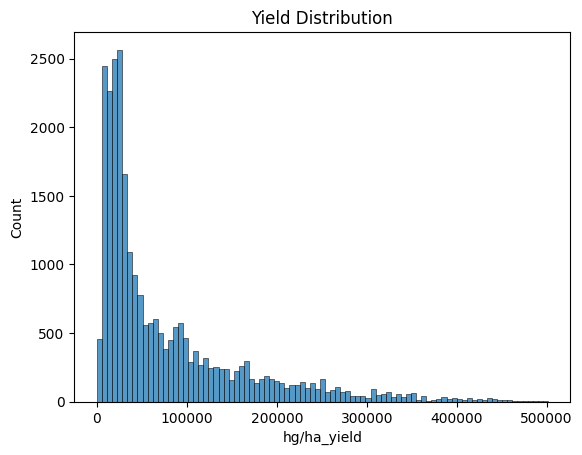

In [ ]:
sns.histplot(final_df['hg/ha_yield'])
plt.title('Yield Distribution')
plt.show()

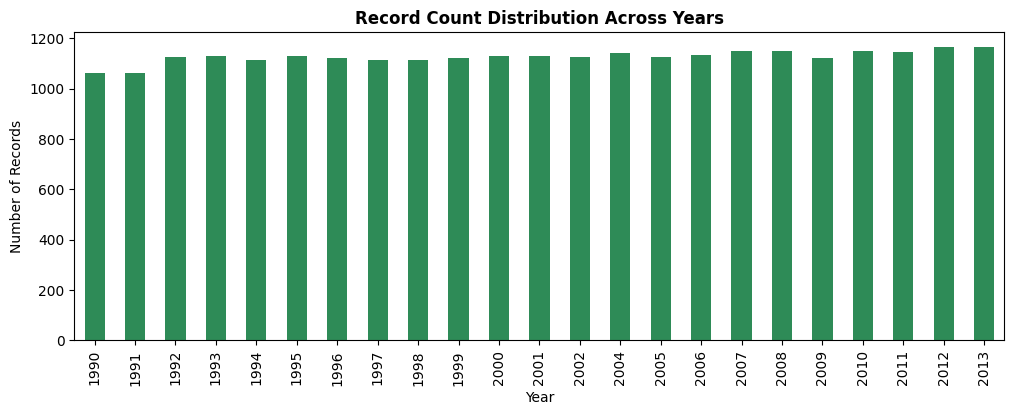

In [ ]:
plt.figure(figsize=(12, 4))
final_df['Year'].value_counts().sort_index().plot(kind='bar', color='seagreen')
plt.title('Record Count Distribution Across Years', fontsize=12, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Number of Records')
plt.show()

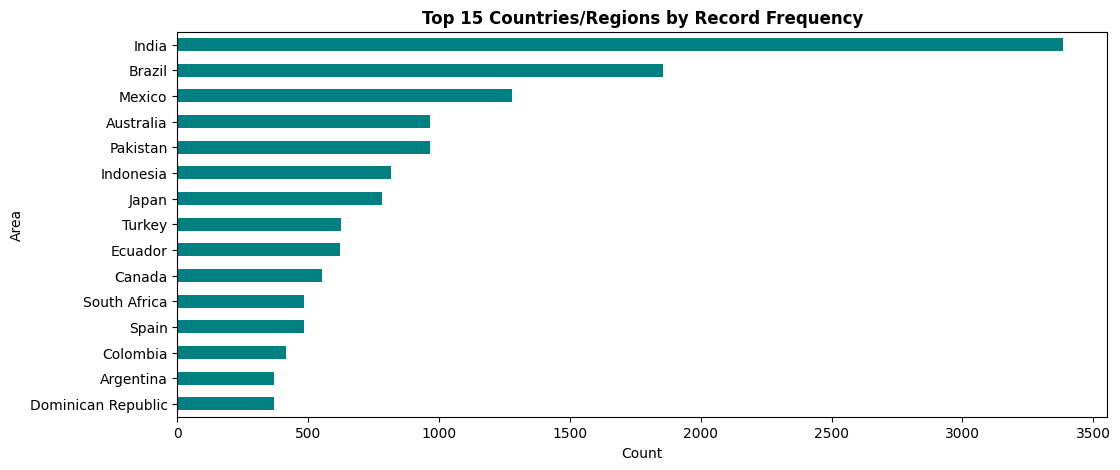

In [ ]:
plt.figure(figsize=(12, 5))
final_df['Area'].value_counts().head(15).plot(kind='barh', color='teal')
plt.title('Top 15 Countries/Regions by Record Frequency', fontsize=12, fontweight='bold')
plt.xlabel('Count')
plt.ylabel('Area')
plt.gca().invert_yaxis()
plt.show()

In [ ]:
yield_skew = final_df['hg/ha_yield'].skew()
print(f'Yield Skewness: {yield_skew:.2f}')

Yield Skewness: 1.81


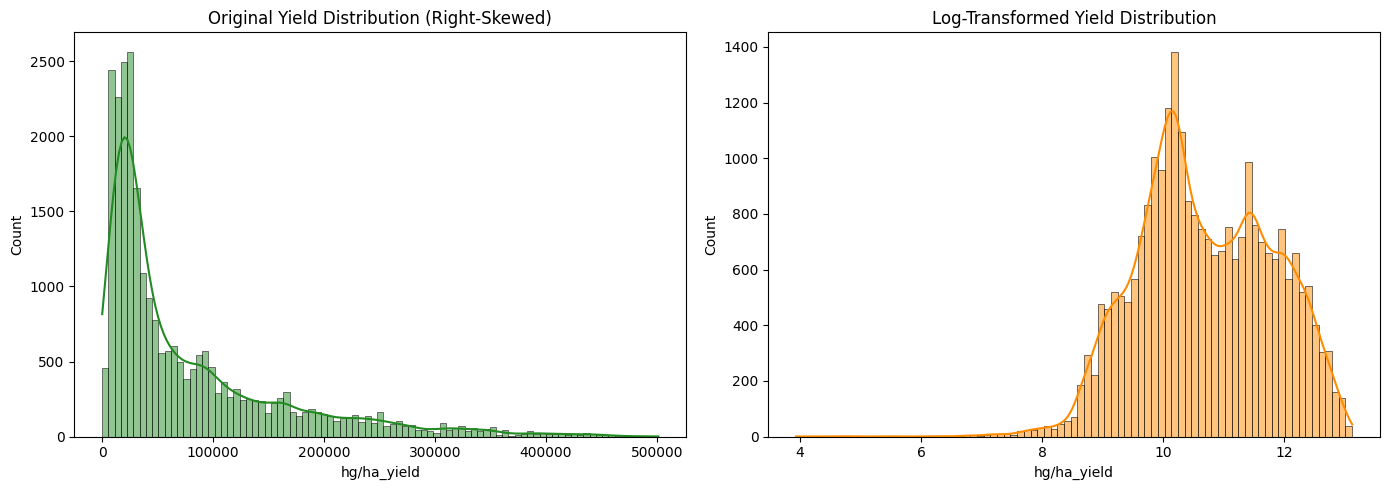

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(final_df['hg/ha_yield'], kde=True, ax=axes[0], color='forestgreen')
axes[0].set_title('Original Yield Distribution (Right-Skewed)')
sns.histplot(np.log1p(final_df['hg/ha_yield']), kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Log-Transformed Yield Distribution')
plt.tight_layout()
plt.show()

In [ ]:
vif_features = ['average_rain_fall_mm_per_year', 'pesticides_tonnes','avg_temp']
X_vif = final_df[vif_features]
X_vif['intercept'] = 1

vif_data = pd.DataFrame()
vif_data['Feature'] = X_vif.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

print(vif_data[vif_data['Feature'] != 'intercept'])

                         Feature       VIF
0  average_rain_fall_mm_per_year  1.153126
1              pesticides_tonnes  1.026857
2                       avg_temp  1.125394


/tmp/ipykernel_2235/3957716273.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_vif['intercept'] = 1


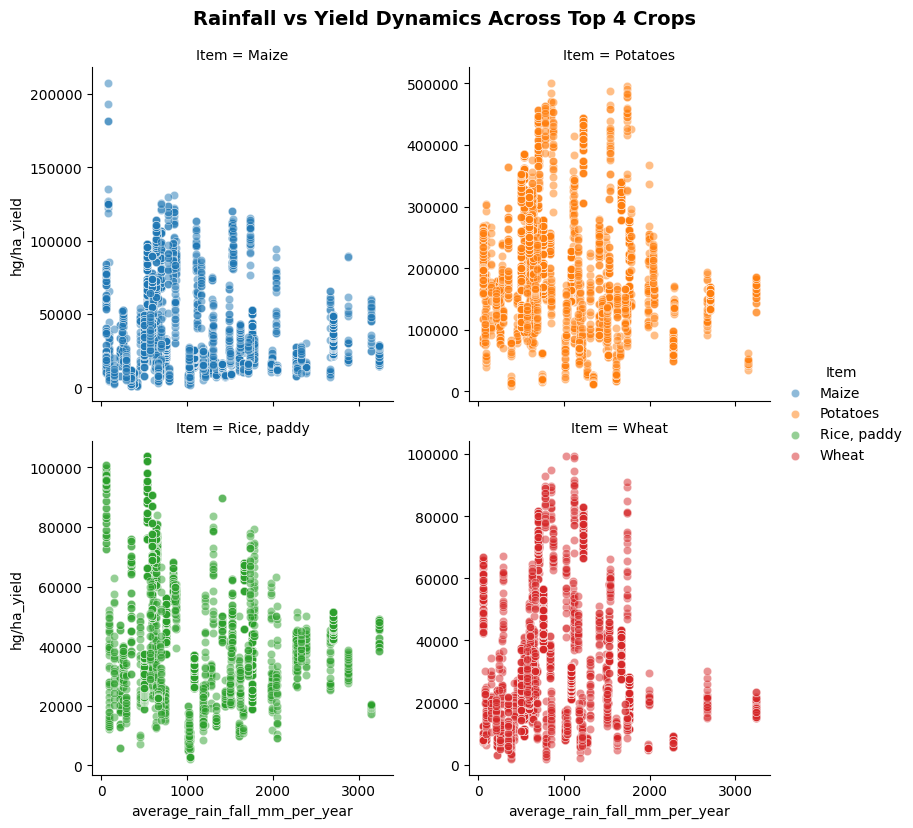

In [ ]:
top_crops = final_df['Item'].value_counts().head(4).index
subset_df = final_df[final_df['Item'].isin(top_crops)]
g = sns.FacetGrid(subset_df, col='Item', hue='Item', col_wrap=2, height=4, sharey=False)
g.map(sns.scatterplot, 'average_rain_fall_mm_per_year', 'hg/ha_yield', alpha=0.5,)
g.add_legend()
plt.suptitle('Rainfall vs Yield Dynamics Across Top 4 Crops', y=1.03, fontsize=14, fontweight='bold')
plt.show()

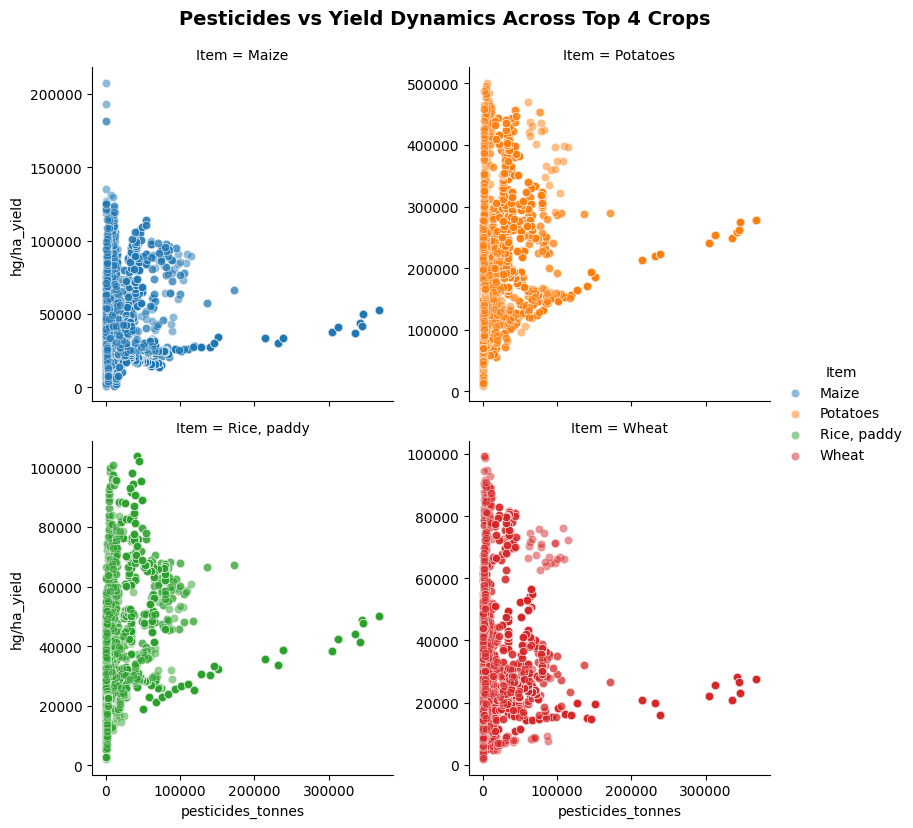

In [ ]:
top_crops = final_df['Item'].value_counts().head(4).index
subset_df = final_df[final_df['Item'].isin(top_crops)]
g = sns.FacetGrid(subset_df, col='Item', hue='Item', col_wrap=2, height=4, sharey=False)
g.map(sns.scatterplot, 'pesticides_tonnes', 'hg/ha_yield', alpha=0.5,)
g.add_legend()
plt.suptitle('Pesticides vs Yield Dynamics Across Top 4 Crops', y=1.03, fontsize=14, fontweight='bold')
plt.show()

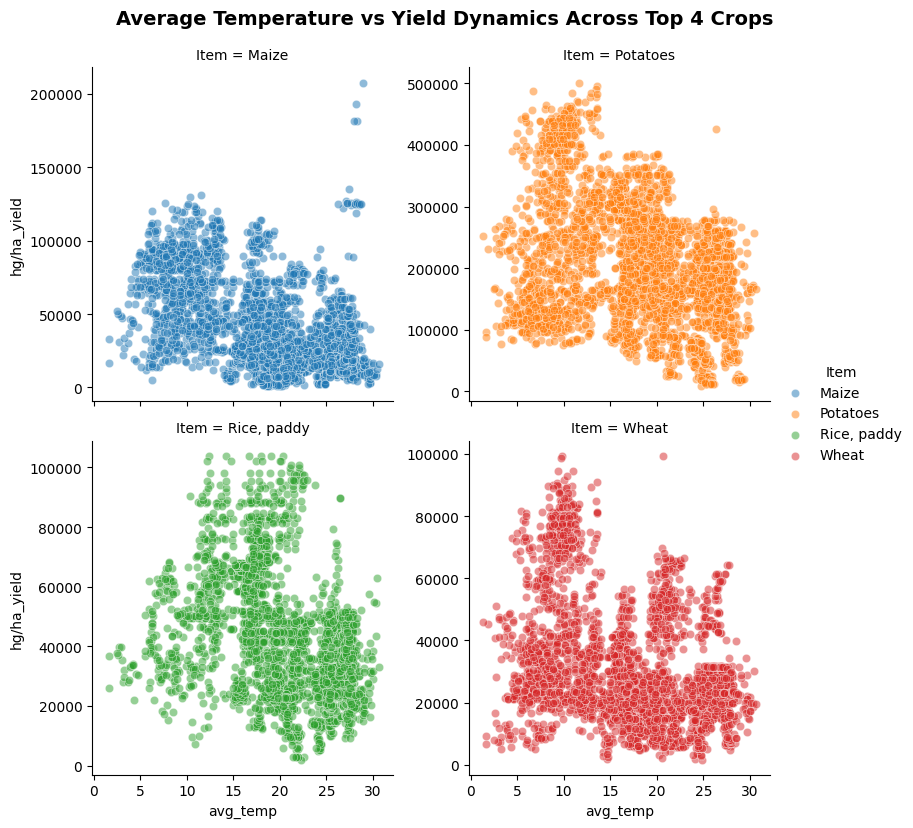

In [ ]:
top_crops = final_df['Item'].value_counts().head(4).index
subset_df = final_df[final_df['Item'].isin(top_crops)]
g = sns.FacetGrid(subset_df, col='Item', hue='Item', col_wrap=2, height=4, sharey=False)
g.map(sns.scatterplot, 'avg_temp', 'hg/ha_yield', alpha=0.5,)
g.add_legend()
plt.suptitle('Average Temperature vs Yield Dynamics Across Top 4 Crops', y=1.03, fontsize=14, fontweight='bold')
plt.show()

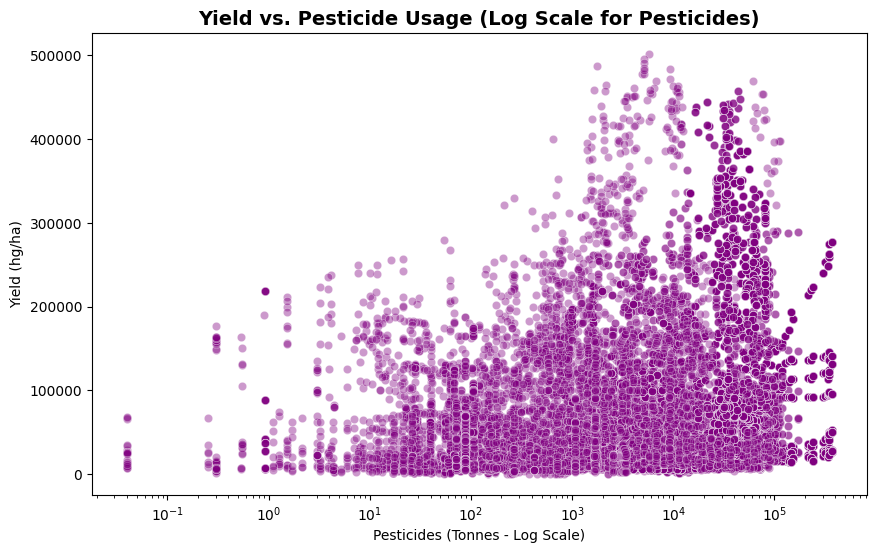

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=final_df, x='pesticides_tonnes', y='hg/ha_yield', alpha=0.4, color='purple')
plt.xscale('log')
plt.title('Yield vs. Pesticide Usage (Log Scale for Pesticides)', fontsize=14, fontweight='bold',)
plt.xlabel('Pesticides (Tonnes - Log Scale)')
plt.ylabel('Yield (hg/ha)')
plt.show()

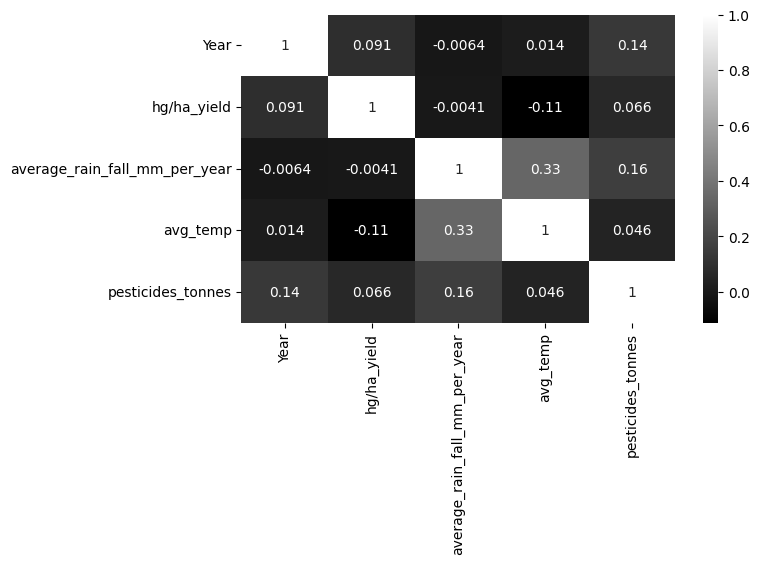

In [ ]:
plt.figure(figsize=(7,4))
sns.heatmap(final_df.corr(numeric_only=True), annot=True, cmap='grey')
plt.show()

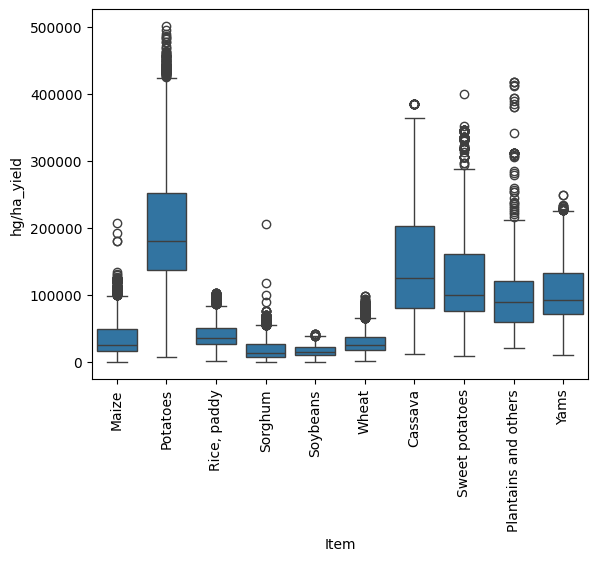

In [ ]:
sns.boxplot(data=final_df, x='Item', y='hg/ha_yield')
plt.xticks(rotation=90)
plt.show()

In [ ]:
categorical_features = ['Area', 'Item']
numerical_features = ['average_rain_fall_mm_per_year', 'avg_temp', 'pesticides_tonnes']

X = final_df[categorical_features + numerical_features]
y = final_df['hg/ha_yield']

In [ ]:
y = np.log1p(y)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7, stratify=final_df['Area'])

In [ ]:
preprocessor = ColumnTransformer(transformers=[('categorical_features', TargetEncoder(target_type='continuous', smooth=10.0), categorical_features,),
        ('numerical_features', StandardScaler(), numerical_features)])

In [ ]:
models_to_tune = {'Linear Regression': {'model': LinearRegression(),'params': {},},
    'Decision Tree': {'model': DecisionTreeRegressor(random_state=7),
        'params': {'model__max_depth': [None, 5, 10, 20],'model__min_samples_split': [2, 5, 10] }},
    'Random Forest': {'model': RandomForestRegressor(random_state=7),
        'params': {'model__n_estimators': [100, 200],'model__max_depth': [15, 25, None], 'model__min_samples_split': [2, 5] } },
    'XGBoost': {'model': XGBRegressor(random_state=7, objective='reg:squarederror'),
        'params': {'model__n_estimators': [50, 100],'model__learning_rate': [0.01, 0.1, 0.2],'model__max_depth': [3, 6] }, },}

In [ ]:
best_models = {}
for name, config in models_to_tune.items():
  print(f'--- Training & Tuning: {name} ---')
  pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', config['model'])])
  cv_fixed = KFold(n_splits=3, shuffle=True, random_state=7)

  grid_search = GridSearchCV(pipeline, config['params'], cv=cv_fixed, scoring='r2', n_jobs=-1)
  grid_search.fit(X_train, y_train)

  print(f'Best Hyperparameters: {grid_search.best_params_}')
  print(f'Best Cross-Validation R2 Score: {grid_search.best_score_:.4f}\n')

  best_models[name] = grid_search.best_estimator_

--- Training & Tuning: Linear Regression ---
Best Hyperparameters: {}
Best Cross-Validation R2 Score: 0.7984

--- Training & Tuning: Decision Tree ---
Best Hyperparameters: {'model__max_depth': 20, 'model__min_samples_split': 10}
Best Cross-Validation R2 Score: 0.9306

--- Training & Tuning: Random Forest ---
Best Hyperparameters: {'model__max_depth': 25, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best Cross-Validation R2 Score: 0.9565

--- Training & Tuning: XGBoost ---
Best Hyperparameters: {'model__learning_rate': 0.2, 'model__max_depth': 6, 'model__n_estimators': 100}
Best Cross-Validation R2 Score: 0.9392



In [ ]:
evaluation_results = {}
print("COMPARING ALL MODELS ON TEST DATA")
for name, model in best_models.items():
    y_pred_log = model.predict(X_test)
    y_pred = np.expm1(y_pred_log)
    y_actual = np.expm1(y_test)
    r2 = r2_score(y_actual, y_pred)
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    evaluation_results[name] = {'R2 Score': r2, 'MAE': mae,'RMSE': rmse}
results_df = pd.DataFrame(evaluation_results).T
print(results_df)
best_model_name = results_df['R2 Score'].idxmax()
best_model = best_models[best_model_name]
print(f"\n The Overall Winner is: {best_model_name} with an R2 of {results_df.loc[best_model_name, 'R2 Score']:.4f}!")

COMPARING ALL MODELS ON TEST DATA
                   R2 Score           MAE          RMSE
Linear Regression  0.710761  24845.389594  45461.808913
Decision Tree      0.957424   7002.137195  17442.213469
Random Forest      0.967109   6507.228553  15330.442928
XGBoost            0.948277  10292.233785  19224.670413

 The Overall Winner is: Random Forest with an R2 of 0.9671!


In [ ]:
# Evaluate R2 score per country on the test set
test_results = X_test.copy()
test_results['actual'] = y_actual
test_results['predicted'] = y_pred

for country in test_results['Area'].unique():
  subset = test_results[test_results['Area'] == country]
  if len(subset) > 10:  # Only for countries with enough test samples
    country_r2 = r2_score(subset['actual'], subset['predicted'])
    print(f'R2 for {country}: {country_r2:.4f}')

R2 for Pakistan: 0.9236
R2 for Chile: 0.8532
R2 for South Africa: 0.9718
R2 for India: 0.9820
R2 for Burundi: 0.8304
R2 for Mexico: 0.9646
R2 for Central African Republic: 0.7254
R2 for Spain: 0.9709
R2 for Canada: 0.8454
R2 for Brazil: 0.9839
R2 for Peru: 0.7666
R2 for Poland: 0.9137
R2 for Japan: 0.9901
R2 for Guatemala: 0.8161
R2 for Libya: 0.9774
R2 for Indonesia: 0.9303
R2 for Nicaragua: 0.8676
R2 for Ecuador: 0.8695
R2 for Haiti: 0.8486
R2 for Turkey: 0.9840
R2 for Mauritania: -0.1407
R2 for Dominican Republic: 0.8032
R2 for Madagascar: 0.9098
R2 for Morocco: 0.9187
R2 for Germany: 0.9756
R2 for Honduras: 0.8907
R2 for Jamaica: 0.9412
R2 for Armenia: 0.8978
R2 for Austria: 0.9868
R2 for Hungary: 0.8272
R2 for Guinea: 0.2227
R2 for Mozambique: 0.6848
R2 for Zimbabwe: 0.8978
R2 for Egypt: 0.9489
R2 for Bangladesh: 0.9069
R2 for Romania: 0.9296
R2 for Italy: 0.9443
R2 for Rwanda: 0.7241
R2 for Kazakhstan: 0.9114
R2 for Australia: 0.9838
R2 for Colombia: 0.9319
R2 for Ukraine: 0.8779

In [ ]:
importances = best_model.named_steps['model'].feature_importances_
features = X_train.columns
feature_df = pd.DataFrame({'Feature': features, 'Importance': importances})
print(feature_df.sort_values(by='Importance', ascending=False))

                         Feature  Importance
1                           Item    0.687662
0                           Area    0.175996
2  average_rain_fall_mm_per_year    0.051517
4              pesticides_tonnes    0.047815
3                       avg_temp    0.037010


In [ ]:
joblib.dump(best_model, 'crop_yield_model.pkl')

['crop_yield_model.pkl']